In [2]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
Original points: 1040913
Points after removing very close neighbors: 859836
Average nearest-neighbor distance: 0.0092 deg
Threshold for removal: 0.0092 deg


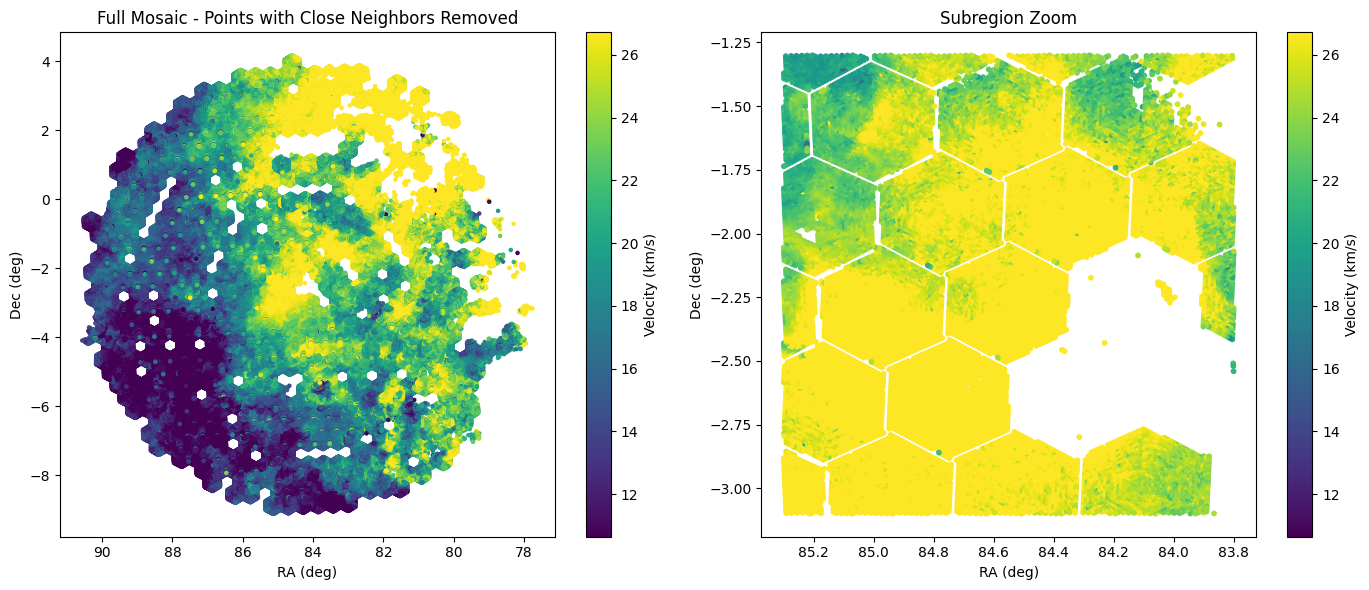

In [3]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# --------------------------------------------------
# Load data
# --------------------------------------------------
hdul = fits.open("LVM_Orion.fits")
table = hdul[1].data
print(table.names)
ra = table['ra'][table['flux_nii']/table['flux_nii_err'] > 8]
dec = table['dec'][table['flux_nii']/table['flux_nii_err'] > 8]
vel = table['vel_nii'][table['flux_nii']/table['flux_nii_err'] > 8]

# --------------------------------------------------
# Convert RA/Dec to projected coordinates
# --------------------------------------------------
ra0 = np.mean(ra)
dec0 = np.mean(dec)

x = (ra - ra0) * np.cos(np.deg2rad(dec0))
y = dec - dec0

coords = np.vstack((x, y)).T

# --------------------------------------------------
# Build KD-tree and compute nearest-neighbor distances
# --------------------------------------------------
tree = cKDTree(coords)
distances, indices = tree.query(coords, k=2)  # k=2 to exclude self
nn_dist = distances[:, 1]  # nearest neighbor distance

# --------------------------------------------------
# Compute average separation and define threshold
# --------------------------------------------------
avg_sep = np.mean(nn_dist)
threshold = 1 * avg_sep  # remove points closer than half the average distance

mask = nn_dist > threshold  # keep points not unusually close

ra_clean = ra[mask]
dec_clean = dec[mask]
vel_clean = vel[mask]

print("Original points:", len(ra))
print("Points after removing very close neighbors:", len(ra_clean))
print("Average nearest-neighbor distance: {:.4f} deg".format(avg_sep))
print("Threshold for removal: {:.4f} deg".format(threshold))

# --------------------------------------------------
# Plot cleaned mosaic
# --------------------------------------------------
plt.figure(figsize=(14, 6))

# Full mosaic
plt.subplot(1, 2, 1)
plt.scatter(ra_clean, dec_clean, c=vel_clean, cmap='viridis', s=5, vmin=np.percentile(vel_clean, 10), vmax=np.percentile(vel_clean, 90))
plt.gca().invert_xaxis()
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
plt.colorbar(label="Velocity (km/s)")
plt.title("Full Mosaic - Points with Close Neighbors Removed")

# Subregion zoom
plt.subplot(1, 2, 2)
ra_min, ra_max = 83.8, 85.3
dec_min, dec_max = -3.1, -1.3
mask_zoom = (ra_clean >= ra_min) & (ra_clean <= ra_max) & (dec_clean >= dec_min) & (dec_clean <= dec_max)
plt.scatter(ra_clean[mask_zoom], dec_clean[mask_zoom], c=vel_clean[mask_zoom], cmap='viridis', s=10, vmin=np.percentile(vel_clean, 10), vmax=np.percentile(vel_clean, 90))
plt.gca().invert_xaxis()
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
plt.colorbar(label="Velocity (km/s)")
plt.title("Subregion Zoom")

plt.tight_layout()
plt.show()

In [4]:
import numpy as np
from scipy.spatial import cKDTree
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import os
from astropy.coordinates import SkyCoord
import astropy.units as u


class VSF2D:
    def __init__(self, ra, dec, vel, dist, coords='angular', vel_err = None):
        if coords == "angular":
            self.ra = ra
            self.dec = dec
            self.vel = vel
            self.vel_err = vel_err if vel_err is not None else np.zeros_like(vel)
            if self.vel_err.size == 0:
                self.vel_err = np.zeros_like(vel)
            coords = SkyCoord(ra=ra*u.deg, dec=dec*u.deg, frame='icrs')
            ref_coord = SkyCoord(ra=coords.ra.mean(), dec=coords.dec.mean(), frame='icrs')

            delta_ra = (coords.ra - ref_coord.ra) * np.cos(ref_coord.dec)
            delta_dec = coords.dec - ref_coord.dec

            x = delta_ra.to(u.arcsec).value
            y = delta_dec.to(u.arcsec).value

            distance = dist * u.pc

            self.x_physical = (x * u.arcsec * distance).to(
                u.pc, equivalencies=u.dimensionless_angles()).value
            self.y_physical = (y * u.arcsec * distance).to(
                u.pc, equivalencies=u.dimensionless_angles()).value
            self.vel_err = vel_err if vel_err is not None else np.zeros_like(vel)
            if self.vel_err.size == 0:
                self.vel_err = np.zeros_like(vel)
            self.x_physical = ra
            self.y_physical = dec

    def determine_length(self, r_min, r_max, bin_resolution=5):
        if r_min <= 0 or r_min >= r_max:
            raise ValueError("Invalid r_min/r_max")
        log_range = np.log10(r_max / r_min)
        return max(int(log_range * bin_resolution), 10)

    def generate_bins_2d(self, data, bin_resolution=80, length=None):

        coords = np.column_stack((data['x'], data['y']))
        tree = cKDTree(coords)

        sample_size = min(1000000, len(coords))
        sample_idx = np.random.choice(len(coords), sample_size, replace=False)
        dists, _ = tree.query(coords[sample_idx], k=2)
        r_min = np.median(dists[:, 1])

        dx = data['x'].max() - data['x'].min()
        dy = data['y'].max() - data['y'].min()
        r_max = np.sqrt(dx**2 + dy**2)

        if length is None:
            length = self.determine_length(r_min, r_max, bin_resolution)

        if r_min <= 0 or r_min >= r_max:
            r_min = r_max / 1000

        log_centers = np.linspace(np.log10(r_min), np.log10(r_max), length)
        return log_centers

    def generate_bins_edges(self, bin_centers):
        bw = np.diff(bin_centers) / 2
        edges = np.empty(len(bin_centers) + 1)
        edges[1:-1] = bin_centers[:-1] + bw
        edges[0] = bin_centers[0] - bw[0]
        edges[-1] = bin_centers[-1] + bw[-1]
        return edges

    def compute_vsf_chunk_2d(self, x, y, vel, vel_err,
                            bin_edges, dv_bins, seed, order):

        rng = np.random.default_rng(seed)
        sample_size = min(10000, len(x))
        idx = rng.choice(len(x), size=sample_size, replace=False)

        x_, y_, vel_, verr_ = x[idx], y[idx], vel[idx], vel_err[idx]
        coords = np.column_stack((x_, y_))

        tree = cKDTree(coords)
        pairs = tree.query_pairs(r=bin_edges[-1], output_type='ndarray')

        nbins = len(bin_edges) - 1
        ndv = len(dv_bins) - 1

        vsf = np.zeros(nbins)
        vsf_sq = np.zeros(nbins)
        vsf_properr = np.zeros(nbins)
        counts = np.zeros(nbins)

        pdf = np.zeros((nbins, ndv))

        # r-only intermittency
        c2_r = np.zeros(nbins)
        c4_r = np.zeros(nbins)
        cnt_r = np.zeros(nbins)

        if pairs.size == 0:
            return vsf, vsf_sq, vsf_properr, counts, pdf, c2_r, c4_r, cnt_r

        i, j = pairs[:, 0], pairs[:, 1]

        dr2 = np.sum((coords[i] - coords[j])**2, axis=1)
        dv = vel_[i] - vel_[j]

        dv_p = np.abs(dv)**order

        pair_err = order * dv**(order - 1) * np.sqrt(verr_[i]**2 + verr_[j]**2)

        # --- r bins ---
        bin_idx = np.searchsorted(bin_edges**2, dr2) - 1
        valid_r = (bin_idx >= 0) & (bin_idx < nbins)

        r_i = bin_idx[valid_r]

        np.add.at(vsf, r_i, dv_p[valid_r])
        np.add.at(vsf_sq, r_i, dv_p[valid_r]**2)
        np.add.at(vsf_properr, r_i, pair_err[valid_r]**2)
        np.add.at(counts, r_i, 1)

        # --- intermittency (r ONLY) ---
        c2 = np.abs(dv)**2
        c4 = np.abs(dv)**4
        np.add.at(c2_r, r_i, c2[valid_r])
        np.add.at(c4_r, r_i, c4[valid_r])
        np.add.at(cnt_r, r_i, 1)

        # --- PDF (KEEP dv_bins) ---
        dv_idx = np.digitize(dv, dv_bins) - 1
        valid_dv = (dv_idx >= 0) & (dv_idx < ndv)

        valid = valid_r & valid_dv
        r_i_pdf = bin_idx[valid]
        dv_i = dv_idx[valid]

        np.add.at(pdf, (r_i_pdf, dv_i), 1)

        return vsf, vsf_sq, vsf_properr, counts, pdf, c2_r, c4_r, cnt_r


    def generate_vsf_2d(self, order, outname, n_jobs=8,
                        min_pairs=3, bin_resolution=80):

        data = {'x': self.x_physical, 'y': self.y_physical}

        log_centers = self.generate_bins_2d(data, bin_resolution)
        edges = self.generate_bins_edges(log_centers)
        bin_edges = 10**edges

        nbins = len(bin_edges) - 1

        dv_min = np.nanmin(self.vel) - np.mean(self.vel)
        dv_max = np.nanmax(self.vel) - np.mean(self.vel)
        dv_bins = np.linspace(dv_min, dv_max, 80)
        ndv = len(dv_bins) - 1

        vsf = np.zeros(nbins)
        vsf_sq = np.zeros(nbins)
        counts = np.zeros(nbins)
        vsf_properr = np.zeros(nbins)

        pdf_all = np.zeros((nbins, ndv))

        c2_all = np.zeros(nbins)
        c4_all = np.zeros(nbins)
        cnt_all = np.zeros(nbins)

        seeds = np.arange(n_jobs)

        results = Parallel(n_jobs=n_jobs)(
            delayed(self.compute_vsf_chunk_2d)(
                self.x_physical, self.y_physical,
                self.vel, self.vel_err,
                bin_edges, dv_bins, seed, order
            ) for seed in seeds
        )

        # --- merge ---
        for vsf_c, vsf_sq_c, err_c, cnt_c, pdf_c, c2_c, c4_c, cnt_r_c in results:
            vsf += vsf_c
            vsf_sq += vsf_sq_c
            vsf_properr += err_c
            counts += cnt_c
            pdf_all += pdf_c

            c2_all += c2_c
            c4_all += c4_c
            cnt_all += cnt_r_c

        # --- VSF ---
        with np.errstate(divide='ignore', invalid='ignore'):
            mean = vsf / counts
            mean_sq = vsf_sq / counts
            var = mean_sq - mean**2

            err = np.sqrt(var / counts)

            vsf = np.where(counts >= min_pairs, mean, np.nan)
            vsf_err = np.where(counts >= min_pairs, err, np.nan)

            # --- INTERMITTENCY (ONLY r) ---
            kk = np.divide(
                c4_all/cnt_all,
                (c2_all/cnt_all)**2,
                out=np.zeros_like(c4_all),
                where=c2_all > 0
            )

        # --- normalize PDF ---
        pdf_sum = np.sum(pdf_all, axis=1, keepdims=True)
        pdf_all = np.divide(pdf_all, pdf_sum, out=np.zeros_like(pdf_all), where=pdf_sum > 0)

        np.savez_compressed(
            outname + f'_order{order}.npz',
            vsf=vsf,
            vsf_err=vsf_err,
            log_centers=log_centers,
            counts=counts,
            pdf=pdf_all,
            dv_bins=dv_bins,
            kk=kk
        )

        return vsf, vsf_err, log_centers, counts
    
    def generate_vsf_ratio_2d(self, outname, n_jobs=8, min_pairs=3, bin_resolution=80):
        """
        Generate and plot the ratio S4 / (S2)^2 of the 2D velocity structure function.

        Parameters:
        -----------
        outname : str
            Output filename (without extension)
        n_jobs : int
            Number of parallel jobs
        min_pairs : int
            Minimum number of pairs required in a bin
        bin_resolution : int
            Resolution of logarithmic binning
        """

        # --- Compute second and fourth order VSFs ---
        vsf2, vsf2err, log_centers, counts2 = self.generate_vsf_2d(
            order=2,
            outname=outname,
            n_jobs=n_jobs,
            min_pairs=min_pairs,
            bin_resolution=bin_resolution
        )

        vsf4,vsf4err, _, counts4 = self.generate_vsf_2d(
            order=4,
            outname=outname,
            n_jobs=n_jobs,
            min_pairs=min_pairs,
            bin_resolution=bin_resolution
        )

        # --- Compute ratio safely ---
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = np.where(
                (vsf2 > 0) & (~np.isnan(vsf2)) & (~np.isnan(vsf4)),
                np.sqrt(vsf4) / vsf2 - 1,
                np.nan
            )

        # Mask bins with insufficient statistics
        valid_counts = np.minimum(counts2, counts4)
        ratio = np.where(valid_counts >= min_pairs, ratio, np.nan)

        # --- Plot ---
        bin_centers_physical = 10**log_centers

        plt.figure(figsize=(8, 6))
        plt.plot(bin_centers_physical, ratio, 'o-', markersize=4, label=r'$S_4 / S_2^2$')

        plt.xscale('log')
        plt.yscale('log')

        plt.xlabel('Separation Distance (pc)', fontsize=12)
        plt.ylabel(r'$S_4 / S_2^2$', fontsize=12)
        plt.title(f'{outname} VSF Ratio (Intermittency Diagnostic)', fontsize=14)

        plt.grid(True, alpha=0.3)
        plt.legend()

        plt.tight_layout()
        print(f"Saving ratio plot to {outname}_ratio.png")
        plt.savefig(outname + '_ratio.png', dpi=300, bbox_inches='tight')
        plt.close()

        print(f"Ratio plot saved to {outname}_ratio.png")

        return ratio, log_centers, valid_counts

    def spatial_map(self, outname):
        """Create a spatial map of the velocity field."""
        plt.figure(figsize=(8, 6))
                # RIGHT PANEL: Velocity Field
        #ax_vel = axes[1]
        
        
        # Velocity field scatter plot
        #sc = ax_vel.scatter(x_clean, y_clean, c=vel_clean, s=5, 
        #                    cmap='RdBu_r', vmin=vmin, vmax=vmax)
        #ax_vel.set_title(f'{outname} Velocity Field', fontsize=14)
        #ax_vel.set_xlabel('x (pc)', fontsize=12)
        #ax_vel.set_ylabel('y (pc)', fontsize=12)
        #ax_vel.set_aspect('equal')
        
        # Add colorbar
        #cbar = plt.colorbar(sc, ax=ax_vel, label='Velocity (km/s)')
        vmin, vmax = np.percentile(self.vel, [20, 80])
        sc = plt.scatter(self.x_physical, self.y_physical, c=self.vel, cmap='RdBu_r', s=8, vmin=vmin, vmax=vmax)
        plt.colorbar(sc, label='Velocity (km/s)')
        plt.xlabel('X (pc)')
        plt.ylabel('Y (pc)')
        plt.title(f'{outname} Velocity Map')
        plt.grid(True, alpha=0.3)
        plt.savefig(outname + '_velocity_map.png', dpi=300, bbox_inches='tight')
        plt.close()
    
    def vel_hist(self, outname):
        """Create a histogram of velocity values."""
        plt.figure(figsize=(8, 6))
        plt.hist(self.vel, bins=80, color='gray', edgecolor='black')
        plt.xlabel('Velocity (km/s)', fontsize=12)
        plt.ylabel('Number of Points', fontsize=12)
        plt.title(f'{outname} Velocity Histogram', fontsize=14)
        plt.yscale('log')

        plt.grid(True, alpha=0.3)

        plt.savefig(outname + '_velocity_histogram.png', dpi=300, bbox_inches='tight')
        plt.savefig(outname + '_velocity_histogram.png', dpi=300, bbox_inches='tight')        
        plt.close()

In [5]:
hdul_names = fits.open("extra_HII_regions.fits")
table_names = hdul_names[1].data
print(table_names.names)
print(table_names['HII Region'])
print(table_names['Heliocentric_distance'])
print(np.asarray(table_names['Heliocentric_distance']) * u.kpc.to(u.pc) * 1e-4)

['WISE', 'Cl', 'GLON', 'GLAT', 'Rad', 'Dist', '_RA_icrs', '_DE_icrs', 'HII Region', 'Halpha flux [1/1e-16]', 'Halpha error [1/1e-16]', 'Hbeta flux [1/1e-16]', 'Hbeta error [1/1e-16]', 'RA [deg]', 'DEC [deg]', 'Heliocentric_distance', 'Distance_error', 'Distance flag [R=Reliable(best), T=Tenative, A=Approximate]', 'ebv', 'ebv_u', 'ebv_d', 'dist_E24', 'dist_E24d', 'dist_E24u', 'dist_Z25', 'dist_Z25d', 'dist_Z25u', 'Separation']
['Sh2-311' 'Gum31' 'RCW52' 'Gum38a' 'RCW60' 'RCW79' 'RCW87' 'BFS65']
[5.28  2.75  2.33  2.5   2.224 4.2   2.7   3.38 ]
[0.528      0.275      0.233      0.25       0.2224     0.42
 0.26999998 0.338     ]


Loaded: NPZ/VSF_Flame_nebula_NII_total_fullfov.npz
Fitting with 37 points after dropping last 1
Bounds used:
  r0:     [0.05282, 10.56]
  m:      [0.5, 2]
  sigma:  [2.768, 22.14]
  bnoise: [0, 1.913]
Best-fit parameters (1-sigma):
r0      = 0.9156 +/- 0.0398
m       = 1.91 +/- 0.195
sigma   = 4.471 +/- 0.149
Bnoise  = 1.113 +/- 0.197


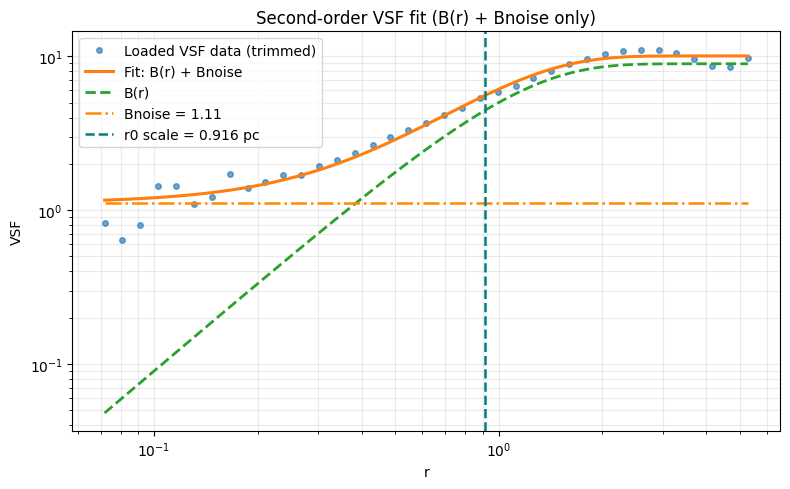

In [45]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Prefer the new full-FOV filename, but allow fallback to previous variant.
npz_candidates = [
    'NPZ/VSF_Flame_nebula_NII_total_fullfov.npz',
    'NPZ/VSF_Flame_nebula_NII_total_fullfov_fast.npz',
]

load_vsf = None
for p in npz_candidates:
    try:
        load_vsf = np.load(p)
        print(f'Loaded: {p}')
        break
    except FileNotFoundError:
        continue

if load_vsf is None:
    raise FileNotFoundError(f'Could not find any of: {npz_candidates}')

def B(r, r0, m, sigma):
    return 2.0 * sigma * (1.0 - 2.0 ** (-(r / r0) ** m))

def model_B_plus_noise(r, r0, m, sigma, bnoise):
    return B(r, r0, m, sigma) + bnoise

# Load radial coordinate and VSF values from NPZ
if 'log_centers' in load_vsf.files:
    r_data = 10 ** load_vsf['log_centers']
elif 'r' in load_vsf.files:
    r_data = load_vsf['r']
else:
    raise KeyError(f"No radial key found in NPZ. Available keys: {load_vsf.files}")

if 'vsf' in load_vsf.files:
    vsf_data = load_vsf['vsf']
elif 'B' in load_vsf.files:
    vsf_data = load_vsf['B']
else:
    raise KeyError(f"No VSF key found in NPZ. Available keys: {load_vsf.files}")

mask = np.isfinite(r_data) & np.isfinite(vsf_data) & (r_data > 0) & (vsf_data > 0)
r_fit = r_data[mask]
vsf_fit = vsf_data[mask]

# Drop the last N largest-scale points before fitting.
n_drop = 1
if r_fit.size <= n_drop + 5:
    raise RuntimeError(f'Not enough points to drop {n_drop}; only {r_fit.size} valid points')

r_fit = r_fit[:-n_drop]
vsf_fit = vsf_fit[:-n_drop]
print(f'Fitting with {len(r_fit)} points after dropping last {n_drop}')

# User-requested bounds for model parameters, computed from trimmed data.
x_max = float(np.nanmax(r_fit))
vsf_max = float(np.nanmax(vsf_fit))
vsf_min = float(np.nanmin(vsf_fit))

r0_lo, r0_hi = 0.01 * x_max, 2.0 * x_max
m_lo, m_hi = 0.5, 2.0
sigma_lo, sigma_hi = 0.25 * vsf_max, 2.0 * vsf_max
bnoise_lo, bnoise_hi = 0.0, 3.0 * vsf_min

print('Bounds used:')
print(f'  r0:     [{r0_lo:.4g}, {r0_hi:.4g}]')
print(f'  m:      [{m_lo:.4g}, {m_hi:.4g}]')
print(f'  sigma:  [{sigma_lo:.4g}, {sigma_hi:.4g}]')
print(f'  bnoise: [{bnoise_lo:.4g}, {bnoise_hi:.4g}]')

# Initial guess inside bounds.
p0 = [
    np.clip(np.nanmedian(r_fit), r0_lo, r0_hi),
    2.0 / 3.0,
    np.clip(np.nanpercentile(vsf_fit, 75) / 2.0, sigma_lo, sigma_hi),
    np.clip(np.nanpercentile(vsf_fit, 10), bnoise_lo, bnoise_hi),
]

lower = [r0_lo, m_lo, sigma_lo, bnoise_lo]
upper = [r0_hi, m_hi, sigma_hi, bnoise_hi]

popt, pcov = curve_fit(
    model_B_plus_noise,
    r_fit,
    vsf_fit,
    p0=p0,
    bounds=(lower, upper),
    maxfev=200000,
 )
perr = np.sqrt(np.diag(pcov))

r0_fit, m_fit, sigma_fit, bnoise_fit = popt

print('Best-fit parameters (1-sigma):')
print(f'r0      = {r0_fit:.4g} +/- {perr[0]:.3g}')
print(f'm       = {m_fit:.4g} +/- {perr[1]:.3g}')
print(f'sigma   = {sigma_fit:.4g} +/- {perr[2]:.3g}')
print(f'Bnoise  = {bnoise_fit:.4g} +/- {perr[3]:.3g}')

r_model = np.logspace(np.log10(np.nanmin(r_fit)), np.log10(np.nanmax(r_fit)), 300)
model = model_B_plus_noise(r_model, *popt)
b_curve = B(r_model, r0_fit, m_fit, sigma_fit)
bnoise_curve = np.full_like(r_model, bnoise_fit)

plt.figure(figsize=(8, 5))
plt.loglog(r_fit, vsf_fit, 'o', ms=4, alpha=0.65, label='Loaded VSF data (trimmed)')
plt.loglog(r_model, model, '-', lw=2.2, label='Fit: B(r) + Bnoise')
plt.loglog(r_model, b_curve, '--', lw=2.0, label='B(r)')
plt.loglog(r_model, bnoise_curve, '-.', lw=1.8, color='darkorange', label=f'Bnoise = {bnoise_fit:.3g}')
plt.axvline(r0_fit, color='teal', ls='--', lw=1.8, label=f'r0 scale = {r0_fit:.3g} pc')
plt.xlabel('r')
plt.ylabel('VSF')
plt.title('Second-order VSF fit (B(r) + Bnoise only)')
plt.grid(True, which='both', alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u

npz_dir = Path('NPZ')
out_dir = Path('Figures/tildeB_fits')
out_dir.mkdir(parents=True, exist_ok=True)

def S(r, r0, s0):
    return (1.0 / (1.0 + 1.25 * s0 / r0)) * (1.0 / (1.0 + (2.6 * s0 / r) ** (1.0 / 5.0)))

def B(r, r0, m, sigma):
    return 2.0 * sigma * (1.0 - 2.0 ** (-(r / r0) ** m))

def tildeB(r, r0, m, sigma, s0, bnoise):
    return S(r, r0, s0) * B(r, r0, m, sigma) + bnoise

def norm_name(s):
    return ''.join(ch for ch in str(s).lower() if ch.isalnum())

# Build object -> distance(pc) lookup from table_names (used only for s0 initial guess)
region_to_pc = {}
for region, d_kpc in zip(table_names['HII Region'], table_names['Heliocentric_distance']):
    try:
        region_to_pc[norm_name(region)] = float(d_kpc) * u.kpc.to(u.pc)
    except Exception:
        continue

def infer_region_key(npz_path):
    stem = npz_path.stem
    if stem.startswith('VSF_'):
        stem = stem[4:]

    parts = stem.split('_')
    tracers = {'NII', 'SII', 'SIII'}
    tracer_idx = None
    for i, p in enumerate(parts):
        if p.upper() in tracers:
            tracer_idx = i
            break

    if tracer_idx is None:
        return norm_name(parts[0]) if parts else ''

    region_parts = parts[:tracer_idx]
    return norm_name('_'.join(region_parts))

results = []
npz_files = sorted(npz_dir.glob('*.npz'))
print(f'Found {len(npz_files)} NPZ files in {npz_dir}')

for f in npz_files:
    try:
        data = np.load(f)

        if 'vsf' in data.files:
            vsf_data = data['vsf']
        elif 'B' in data.files:
            vsf_data = data['B']
        else:
            print(f'SKIP {f.name}: missing vsf/B key')
            continue

        if 'log_centers' in data.files:
            r_data = 10 ** data['log_centers']
        elif 'r' in data.files:
            r_data = data['r']
        else:
            print(f'SKIP {f.name}: missing log_centers/r key')
            continue

        mask = np.isfinite(r_data) & np.isfinite(vsf_data) & (r_data > 0) & (vsf_data > 0)
        r_fit = r_data[mask]
        vsf_fit = vsf_data[mask]

        if r_fit.size < 8:
            print(f'SKIP {f.name}: not enough valid points ({r_fit.size})')
            continue

        # Optional object-based initial guess for s0, but s0 remains a free fitted parameter
        region_key = infer_region_key(f)
        d_pc_guess = region_to_pc.get(region_key, np.nan)
        s0_guess = d_pc_guess * 4e-6 if np.isfinite(d_pc_guess) else np.nanmedian(r_fit) / 5.0
        s0_guess = max(float(s0_guess), 1e-6)

        p0 = [
            np.nanmedian(r_fit),
            2.0 / 3.0,
            np.nanpercentile(vsf_fit, 75) / 2.0,
            s0_guess,
            np.nanpercentile(vsf_fit, 10),
        ]
        bounds = ([1e-4, 0.05, 0.0, 1e-6, -np.inf], [np.inf, 5.0, np.inf, np.inf, np.inf])

        popt, pcov = curve_fit(tildeB, r_fit, vsf_fit, p0=p0, bounds=bounds, maxfev=40000)
        perr = np.sqrt(np.diag(pcov))

        r_model = np.logspace(np.log10(np.nanmin(r_fit)), np.log10(np.nanmax(r_fit)), 300)
        y_model = tildeB(r_model, *popt)
        b_curve = B(r_model, popt[0], popt[1], popt[2])

        plt.figure(figsize=(7.5, 5))
        plt.loglog(r_fit, vsf_fit, 'o', ms=3.5, alpha=0.6, label='Data')
        plt.loglog(r_model, y_model, '-', lw=2.0, label='tildeB fit (s0 free)')
        plt.loglog(r_model, b_curve, '--', lw=1.8, label='B(r)')
        plt.xlabel('r')
        plt.ylabel('VSF')
        plt.title(f'{f.stem} | fit s0={popt[3]:.3g}')
        plt.grid(True, which='both', alpha=0.25)
        plt.legend()
        plt.tight_layout()
        plt.savefig(out_dir / f'{f.stem}_fit.png', dpi=180)
        plt.close()

        results.append({
            'file': f.name,
            'region_key': region_key,
            'distance_pc_guess': d_pc_guess,
            'r0': popt[0],
            'r0_err': perr[0],
            'm': popt[1],
            'm_err': perr[1],
            'sigma': popt[2],
            'sigma_err': perr[2],
            's0': popt[3],
            's0_err': perr[3],
            'Bnoise': popt[4],
            'Bnoise_err': perr[4],
            'npts': int(r_fit.size),
        })

        print(f'OK   {f.name}: r0={popt[0]:.3g}, m={popt[1]:.3g}, sigma={popt[2]:.3g}, s0={popt[3]:.3g}, Bnoise={popt[4]:.3g}')

    except Exception as e:
        print(f'FAIL {f.name}: {e}')

print(f'Completed: {len(results)} successful fits, plots saved in {out_dir}')
if results:
    for row in sorted(results, key=lambda x: x['file'])[:10]:
        print(row['file'], f"m={row['m']:.3f}", f"r0={row['r0']:.3f}", f"s0={row['s0']:.3g}")

Found 151 NPZ files in NPZ
OK   Orion_NII_order2.npz: r0=3.26, m=1.68, sigma=502, s0=1e-06, Bnoise=70.1
OK   VSF_BFS65_NII.npz: r0=7.92e+04, m=0.575, sigma=2.51e+03, s0=1e-06, Bnoise=4.37
OK   VSF_BFS65_NII_exclude_peak.npz: r0=33.9, m=0.829, sigma=42.9, s0=1e-06, Bnoise=4.86
OK   VSF_BFS65_NII_include_peak.npz: r0=7.92e+04, m=0.575, sigma=2.51e+03, s0=1e-06, Bnoise=4.37
OK   VSF_BFS65_NII_mean_allsubwindows.npz: r0=7.92e+04, m=0.575, sigma=2.51e+03, s0=1e-06, Bnoise=4.37
OK   VSF_BFS65_NII_median_allsubwindows.npz: r0=2.25e+04, m=0.697, sigma=2.9e+03, s0=1e-06, Bnoise=4.68
OK   VSF_BFS65_SII.npz: r0=2.57, m=1.82, sigma=6.96, s0=1e-06, Bnoise=9.86
OK   VSF_BFS65_SIII.npz: r0=1.56, m=5, sigma=23.1, s0=1e-06, Bnoise=11.1
OK   VSF_BFS65_SIII_exclude_peak.npz: r0=1.57, m=5, sigma=23.7, s0=1e-06, Bnoise=10.1
OK   VSF_BFS65_SIII_include_peak.npz: r0=1.56, m=5, sigma=23.1, s0=1e-06, Bnoise=11.1
OK   VSF_BFS65_SIII_mean_allsubwindows.npz: r0=1.56, m=5, sigma=23.1, s0=1e-06, Bnoise=11.1
OK   VS

In [125]:
for index, region in enumerate(table_names['HII Region']):
    hdul = fits.open(f"LVM_{region}.fits")
    table = hdul[1].data
    for line in ['nii', 'sii', 'siii']:
        filter = table[f'flux_{line}']/table[f'flux_{line}_err'] > 5
        vsf = VSF2D(table['ra'][filter], table['dec'][filter], table[f'vel_{line}'][filter], float(table_names['Heliocentric_distance'][index])*1e3)
        #vsf.vel_hist(outname=f'Figures/{region}_{line.upper()}')
        #vsf.spatial_map(outname=f'Figures/{region}_{line.upper()}')
        for order in [1,2]:

            #vsf.generate_vsf_ratio_2d(outname=f'Figures/{region}_{line.upper()}', bin_resolution=20)
            if 'lsf_niii' in table.names:
                disp_corr = np.sqrt((table['disp_nii']/6583.*3e5)**2 - (table['lsf_nii']/2.354/6583.*3e5)**2)
                turb_sq = disp_corr**2 - 13**2
                turb = np.sqrt(np.maximum(turb_sq, 0))

                print(f"Dispersion measurements: {table['disp_nii']/6583.*3e5} \n \
                       LSF corrections: {table['lsf_nii']/2.354/6583.*3e5} \n")
                print(f"Max turbulence: {np.nanpercentile(turb, 75):.2f} km/s")
                print(f"Min turbulence: {np.nanpercentile(turb, 25):.2f} km/s")
                print(f"dispersion corrections: {disp_corr} km/s")
                subres = True
                vsub = [np.nanpercentile(turb, 75), np.nanpercentile(turb, 25)]
                cvalues = table['disp_nii_err'] / 6583. * 3e5

                idx75 = np.where(np.isclose(vsub, np.nanpercentile(vsub, 75), rtol=1e-3, atol=1e-6))[0]
                idx25 = np.where(np.isclose(vsub, np.nanpercentile(turb, 25), rtol=1e-3, atol=1e-6))[0]
                vsub_err_max = cvalues[idx75] if len(idx75) > 0 else 0
                vsub_err_min = cvalues[idx25] if len(idx25) > 0 else vsub_err_max
                    # if you need a scalar:
                vsub_err = [vsub_err_min, vsub_err_max]
            else: subres = False; vsub = [0,0]; vsub_err = [0,0]
            vsf.generate_vsf_2d(order=order, outname=f'Figures/{region}_{line.upper()}', subres=subres, vsub=vsub, vsub_err = vsub_err, bin_resolution=20)

             

Saving plot to  Figures/Sh2-311_NII_order1.png
Saving plot to  Figures/Sh2-311_NII_order2.png
Saving plot to  Figures/Sh2-311_SII_order1.png
Saving plot to  Figures/Sh2-311_SII_order2.png
Saving plot to  Figures/Sh2-311_SIII_order1.png
Saving plot to  Figures/Sh2-311_SIII_order2.png
Saving plot to  Figures/Gum31_NII_order1.png
Saving plot to  Figures/Gum31_NII_order2.png
Saving plot to  Figures/Gum31_SII_order1.png
Saving plot to  Figures/Gum31_SII_order2.png
Saving plot to  Figures/Gum31_SIII_order1.png
Saving plot to  Figures/Gum31_SIII_order2.png
Saving plot to  Figures/RCW52_NII_order1.png
Saving plot to  Figures/RCW52_NII_order2.png
Saving plot to  Figures/RCW52_SII_order1.png
Saving plot to  Figures/RCW52_SII_order2.png
Saving plot to  Figures/RCW52_SIII_order1.png
Saving plot to  Figures/RCW52_SIII_order2.png
Saving plot to  Figures/Gum38a_NII_order1.png
Saving plot to  Figures/Gum38a_NII_order2.png
Saving plot to  Figures/Gum38a_SII_order1.png
Saving plot to  Figures/Gum38a_SII

/Users/fernando/.myvenv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Saving plot to  Figures/RCW79_NII_order2.png
Saving plot to  Figures/RCW79_SII_order1.png
Saving plot to  Figures/RCW79_SII_order2.png
Saving plot to  Figures/RCW79_SIII_order1.png
Saving plot to  Figures/RCW79_SIII_order2.png
Saving plot to  Figures/RCW87_NII_order1.png
Saving plot to  Figures/RCW87_NII_order2.png
Saving plot to  Figures/RCW87_SII_order1.png
Saving plot to  Figures/RCW87_SII_order2.png
Saving plot to  Figures/RCW87_SIII_order1.png
Saving plot to  Figures/RCW87_SIII_order2.png
Saving plot to  Figures/BFS65_NII_order1.png
Saving plot to  Figures/BFS65_NII_order2.png
Saving plot to  Figures/BFS65_SII_order1.png
Saving plot to  Figures/BFS65_SII_order2.png
Saving plot to  Figures/BFS65_SIII_order1.png
Saving plot to  Figures/BFS65_SIII_order2.png


[20.16334483  2.76083171  2.89611159  5.80883561  3.6658554  13.04298424
 12.80466299  5.09699171  9.6105876   9.72459309  6.86657616  8.10146087
  6.54514928  6.4214974   5.93748227  5.66899754  5.74184715  5.66584133
  5.51991036  5.41472914  5.33654305  5.20037617  4.93251283  4.56411736
  4.17198826  3.77222187  3.41891349  3.13274698  2.95842935  2.8428343
  2.7597161   2.73375504  2.79806277  2.98525829  3.03506954  2.9442525
  3.0041415   2.67046075  0.          0.          0.        ]


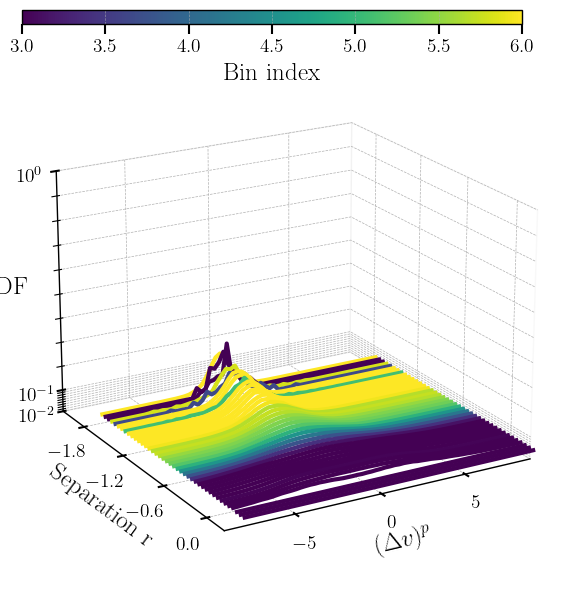

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.ticker import MaxNLocator

plt.style.use('kurtosis_plot.mplstyle')

data = np.load('Figures/Flame_NII_order1.npz')

pdf = data["pdf"]
dv_bins = data["dv_bins"]
log_centers = data["log_centers"]
kk = data['kk']

dv_centers = 0.5 * (dv_bins[:-1] + dv_bins[1:])
r = 10**log_centers

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# ----------------------------
# YOUR DATA PLOT
# ----------------------------
cmap = cm.viridis
norm = plt.Normalize(3, 6)
print(kk)

x_min, x_max = -10, 10

for i in range(len(r)):
    color = cmap(norm(kk[i]))

    mask = (dv_centers >= x_min) & (dv_centers <= x_max)

    ax.plot(
        dv_centers[mask],
        np.log10(np.full(np.sum(mask), r[i])),
        pdf[i][mask],
        color=color
    )


# ----------------------------
# LABELS
# ----------------------------
ax.set_xlabel(r"$(\Delta v)^p$")
ax.set_ylabel("Separation r")
ax.set_zlabel("PDF")
ax.set_xlim(9, -9)

ax.view_init(elev=20, azim=60)
ax.dist = 10
ax.set_zscale('log')
ax.set_zlim(1e-2, max(pdf.flatten())*1.5)

# ----------------------------
# TICKS
# ----------------------------
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))


ax.tick_params(axis='both', which='major')


# ----------------------------
# CLEAN PANE STYLE
# ----------------------------
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

# ----------------------------
# COLORBAR
# ----------------------------
mappable = cm.ScalarMappable(cmap=cmap, norm=norm)
mappable.set_array([])

# ----------------------------
# COLORBAR (TOP)
# ----------------------------
mappable = cm.ScalarMappable(cmap=cmap, norm=norm)
mappable.set_array([])

# [left, bottom, width, height] in figure coordinates
cax = fig.add_axes([0.25, 0.92, 0.5, 0.02])

cbar = plt.colorbar(mappable, cax=cax, orientation='horizontal')
cbar.set_label("Bin index", labelpad=5)


plt.show()

In [299]:
hdul = fits.open("LVM_Flame_nebula.fits")
table = hdul[1].data
filter = table[f'flux_nii']/table[f'flux_nii_err'] > 5
vsf = VSF2D(table['ra'][filter], table['dec'][filter], table['vel_nii'][filter],  dist=400, vel_err = table['vel_nii_err'][filter])
#vsf.spatial_map(outname='LVM_Flame_NII')
vsf.generate_vsf_2d(order=1, outname='Figures/Flame_NII', bin_resolution = 20)

(array([0.63289483, 0.63519038, 0.69136087, 0.85248723, 0.92444604,
        0.74983547, 0.78671036, 0.95255502, 0.86028904, 0.89958295,
        0.96148187, 0.96242792, 1.03073303, 1.08526708, 1.14585824,
        1.22204377, 1.29292081, 1.36330558, 1.44641582, 1.53453376,
        1.61611311, 1.73986255, 1.8323951 , 1.93081485, 2.07120197,
        2.20790009, 2.34437354, 2.4732885 , 2.57996667, 2.65546138,
        2.70958624, 2.71991464, 2.66181563, 2.53809327, 2.42726699,
        2.4062148 , 2.55794625, 3.16157551,        nan,        nan,
               nan]),
 array([0.00186389, 0.02372885, 0.02103027, 0.01250662, 0.02303493,
        0.00214093, 0.00220377, 0.01113505, 0.00168522, 0.00241194,
        0.00247445, 0.00182674, 0.00158575, 0.00164771, 0.00137327,
        0.00145257, 0.00140218, 0.00122455, 0.00123811, 0.00115906,
        0.00101246, 0.00110902, 0.00101006, 0.00090421, 0.00087541,
        0.00083441, 0.00077942, 0.00074304, 0.00070761, 0.00067367,
        0.00063643, 0.0006

In [278]:
rosette_hdul = fits.open("LVM_Orion.fits")
table_rosette = rosette_hdul[1].data
filter = table_rosette[f'flux_nii']/table_rosette[f'flux_nii_err'] > 5
vsf = VSF2D(table_rosette['ra'][filter], table_rosette['dec'][filter], table_rosette['vel_nii'][filter], dist=1500, vel_err = table_rosette['vel_nii_err'][filter])
vsf.generate_vsf_2d(order=1, outname='Figures/Orion_NII', bin_resolution=30)

(array([ 1.04658793,  1.48614082,  1.70071786,  1.40772414,  1.40152292,
         1.40958231,  1.2363871 ,  1.15949298,  1.23064085,  1.27377295,
         1.56611643,  1.60949336,  1.23483823,  1.28342293,  1.28493923,
         1.65684085,  1.33847841,  1.42403436,  1.42620575,  1.44506639,
         1.45805132,  1.46507021,  1.59890473,  1.53438277,  1.62016581,
         1.62637544,  1.65972565,  1.73164549,  1.72666547,  1.77396388,
         1.83396765,  1.91064546,  1.93808033,  1.96977455,  2.02774684,
         2.09479399,  2.15169001,  2.21457054,  2.27789619,  2.32893482,
         2.39079601,  2.47139573,  2.5488988 ,  2.61448151,  2.67956584,
         2.76057467,  2.82039738,  2.8918737 ,  2.96129039,  3.03260927,
         3.10076952,  3.16655417,  3.23831688,  3.30284267,  3.38171645,
         3.45381818,  3.53779474,  3.62220562,  3.72357573,  3.81272294,
         3.9100657 ,  4.00711635,  4.09751738,  4.1794149 ,  4.26715657,
         4.36618306,  4.49157611,  4.63136863,  4.7

In [4]:
class VSF2DSubwindows(VSF2D):
    def __init__(self, ra, dec, vel, dist):
        super().__init__(ra, dec, vel, dist)

    def generate_subwindows(self, window_size, min_points=50,
                        fill_fraction=0.7, n_sub=5):
        """
        Divide the spatial domain into subwindows and keep only 'filled' ones.

        Parameters
        ----------
        window_size : float
        min_points : int
            Minimum number of points
        fill_fraction : float
            Fraction of subcells that must contain data (0–1)
        n_sub : int
            Number of subdivisions per axis (grid = n_sub x n_sub)
        """

        x = self.x_physical.value
        y = self.y_physical.value

        xmin, xmax = x.min(), x.max()
        ymin, ymax = y.min(), y.max()

        x_edges = np.arange(xmin, xmax + window_size, window_size)
        y_edges = np.arange(ymin, ymax + window_size, window_size)

        windows = []

        for i in range(len(x_edges)-1):
            for j in range(len(y_edges)-1):

                mask = (
                    (x >= x_edges[i]) & (x < x_edges[i+1]) &
                    (y >= y_edges[j]) & (y < y_edges[j+1])
                )

                if np.sum(mask) < min_points:
                    continue

                # --- check spatial filling ---
                xw = x[mask]
                yw = y[mask]

                # create subgrid inside window
                sub_x = np.linspace(x_edges[i], x_edges[i+1], n_sub+1)
                sub_y = np.linspace(y_edges[j], y_edges[j+1], n_sub+1)

                occupied = 0
                total_cells = n_sub * n_sub

                for ii in range(n_sub):
                    for jj in range(n_sub):

                        submask = (
                            (xw >= sub_x[ii]) & (xw < sub_x[ii+1]) &
                            (yw >= sub_y[jj]) & (yw < sub_y[jj+1])
                        )

                        if np.any(submask):
                            occupied += 1

                if occupied / total_cells >= fill_fraction:
                    windows.append((i, j, mask))

        return windows, x_edges, y_edges
    
    def compute_subwindow_vsfs(self, window_size, order=2, n_jobs=4, bin_resolution=60):

        windows, x_edges, y_edges = self.generate_subwindows(window_size)

        results = []

        for i, j, mask in windows:

            x = self.x_physical.value[mask]
            y = self.y_physical.value[mask]
            vel = self.vel[mask]

            data = {'x': x, 'y': y}

            log_centers = self.generate_bins_2d(data, bin_resolution=bin_resolution)
            edges = self.generate_bins_edges(log_centers)
            bin_edges = 10**edges

            vsf = np.zeros(len(bin_edges)-1)
            counts = np.zeros_like(vsf)

            seeds = np.arange(n_jobs)

            chunks = Parallel(n_jobs=n_jobs)(
                delayed(self.compute_vsf_chunk_2d)(x, y, vel, bin_edges, seed, order)
                for seed in seeds
            )

            for v, c in chunks:
                vsf += v
                counts += c

            with np.errstate(divide='ignore'):
                vsf = np.where(counts > 0, vsf/counts, np.nan)

            results.append((i, j, vsf, log_centers))

        return results, x_edges, y_edges
    
    def plot_subwindow_vsfs(self, window_size, outname, order=2,
                       alpha=0.15, show_mean=True, n_common=60):

        results, x_edges, y_edges = self.compute_subwindow_vsfs(window_size, order)

        fig, ax = plt.subplots(figsize=(7, 6))

        all_interp_vsfs = []

        # --- define common grid (log space) ---
        r_min = np.inf
        r_max = 0

        for _, _, _, log_centers in results:
            r = 10**log_centers
            r_min = min(r_min, r.min())
            r_max = max(r_max, r.max())

        common_r = np.logspace(np.log10(r_min), np.log10(r_max), n_common)

        # --- plot individual curves ---
        for i, j, vsf, log_centers in results:

            r = 10**log_centers

            ax.plot(r, vsf, '-', color='C0', alpha=alpha, linewidth=1)

            # interpolate onto common grid
            interp = np.interp(common_r, r, vsf, left=np.nan, right=np.nan)
            all_interp_vsfs.append(interp)

        # --- mean curve ---
        if show_mean and len(all_interp_vsfs) > 0:

            all_interp_vsfs = np.array(all_interp_vsfs)

            mean_vsf = np.nanmean(all_interp_vsfs, axis=0)

            ax.plot(common_r, mean_vsf, color='black', linewidth=2.5,
                    label='Mean VSF')
            
            slope = order / 3.0

            # choose a pivot point for normalization (middle of range)
            mid = len(common_r) // 2

            ref = common_r**slope

            # normalize to match mean VSF at midpoint
            ref *= mean_vsf[mid] / ref[mid]

            ax.plot(common_r, ref, '--', color='green', linewidth=2,
                    label=f'r^{order}/3')


            ax.legend()

        # --- formatting ---
        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlabel("Separation (pc)")
        ax.set_ylabel("VSF")
        ax.set_title("Subwindow VSFs (overlaid)")

        plt.tight_layout()
        plt.savefig(outname + "_subwindow_vsfs_overlay.png", dpi=300)
        plt.show()
        plt.close()

    from matplotlib.patches import Rectangle, Circle

    def plot_subwindows_fov(self, window_size, shape="square", show_all=True):
        """
        Visualize the full FOV and the selected subwindows.

        Parameters
        ----------
        window_size : float
            Size of each subwindow (same units as x_physical, y_physical)
        shape : str
            "square" (default) or "circle"
        show_all : bool
            If True, draw all grid cells faintly; otherwise only valid ones
        """

        x = self.x_physical.value
        y = self.y_physical.value

        windows, x_edges, y_edges = self.generate_subwindows(window_size)

        fig, ax = plt.subplots(figsize=(8, 8))

        # --- plot all points ---
        ax.scatter(x, y, s=2, alpha=0.3, color='black')

        # --- optionally draw full grid ---
        if show_all and shape == "square":
            for i in range(len(x_edges)-1):
                for j in range(len(y_edges)-1):
                    rect = Rectangle(
                        (x_edges[i], y_edges[j]),
                        window_size,
                        window_size,
                        linewidth=0.5,
                        edgecolor='gray',
                        facecolor='none',
                        alpha=0.3
                    )
                    ax.add_patch(rect)

        # --- highlight selected windows ---
        for i, j, mask in windows:

            if shape == "square":
                rect = Rectangle(
                    (x_edges[i], y_edges[j]),
                    window_size,
                    window_size,
                    linewidth=1.5,
                    edgecolor='red',
                    facecolor='none'
                )
                ax.add_patch(rect)

            elif shape == "circle":
                cx = 0.5 * (x_edges[i] + x_edges[i+1])
                cy = 0.5 * (y_edges[j] + y_edges[j+1])

                circ = Circle(
                    (cx, cy),
                    radius=window_size / 2,
                    linewidth=1.5,
                    edgecolor='blue',
                    facecolor='none'
                )
                ax.add_patch(circ)

        ax.set_xlabel("x (pc)")
        ax.set_ylabel("y (pc)")
        ax.set_title("FOV with Subwindows")

        ax.set_aspect('equal')
        plt.tight_layout()
        plt.show()

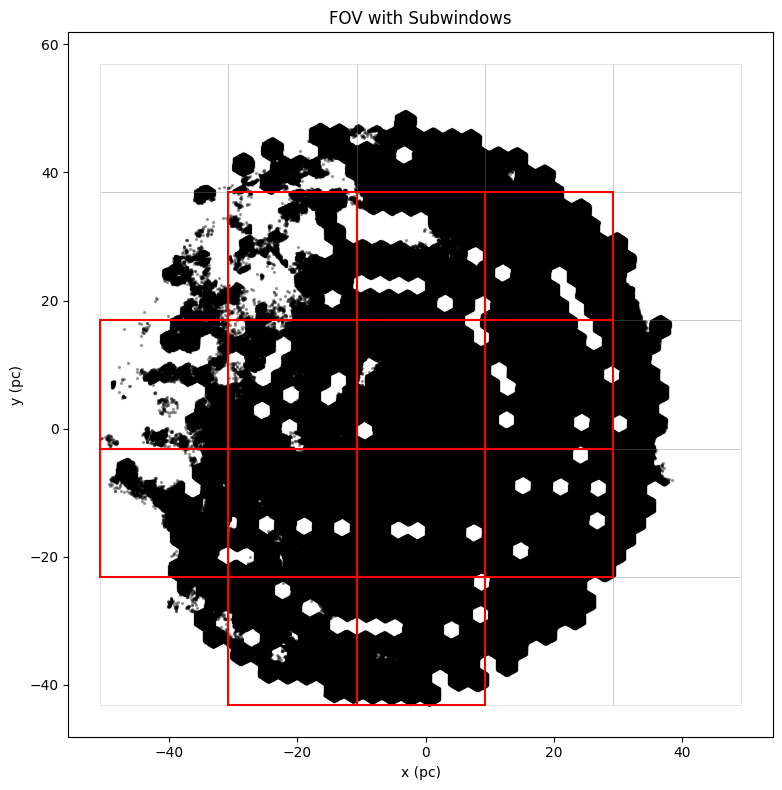

Determining number of bins based on r_max=5.03e+01 pc and bin_resolution=60 per decade.
Generating 102 logarithmic bins from r_min=7.18e-02 pc to r_max=5.03e+01 pc.


/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_61445/465313426.py:103: RuntimeWarning: invalid value encountered in divide
  vsf = np.where(counts > 0, vsf/counts, np.nan)


Determining number of bins based on r_max=5.08e+01 pc and bin_resolution=60 per decade.
Generating 102 logarithmic bins from r_min=7.18e-02 pc to r_max=5.08e+01 pc.
Determining number of bins based on r_max=4.69e+01 pc and bin_resolution=60 per decade.
Generating 100 logarithmic bins from r_min=7.19e-02 pc to r_max=4.69e+01 pc.
Determining number of bins based on r_max=3.84e+01 pc and bin_resolution=60 per decade.
Generating 95 logarithmic bins from r_min=7.18e-02 pc to r_max=3.84e+01 pc.
Determining number of bins based on r_max=3.46e+01 pc and bin_resolution=60 per decade.
Generating 92 logarithmic bins from r_min=7.18e-02 pc to r_max=3.46e+01 pc.
Determining number of bins based on r_max=4.71e+01 pc and bin_resolution=60 per decade.
Generating 100 logarithmic bins from r_min=7.18e-02 pc to r_max=4.71e+01 pc.
Determining number of bins based on r_max=4.37e+01 pc and bin_resolution=60 per decade.
Generating 98 logarithmic bins from r_min=7.19e-02 pc to r_max=4.37e+01 pc.
Determining n

/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_61445/465313426.py:145: RuntimeWarning: Mean of empty slice
  mean_vsf = np.nanmean(all_interp_vsfs, axis=0)


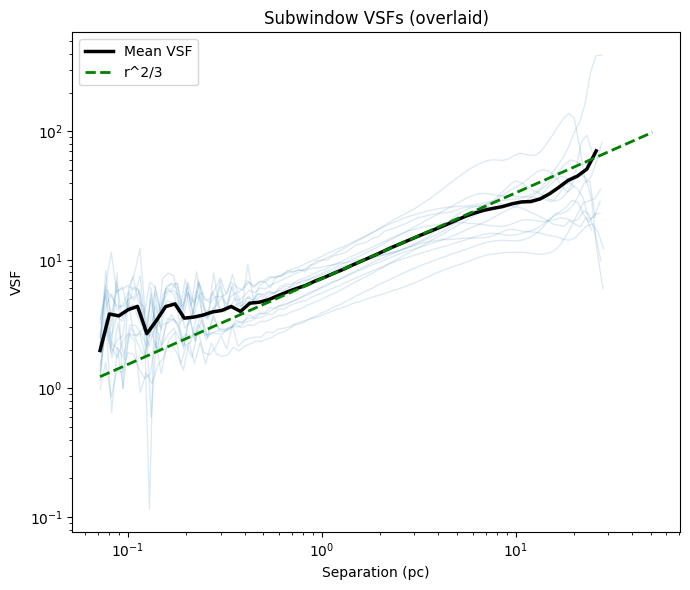

In [28]:
vsf = VSF2DSubwindows(ra, dec, vel, 400)

#vsf.plot_subwindow_vsfs(
#    window_size=10,   # pc
#    outname="vsf_windows_Orion",
#    order=2
#)

vsf.plot_subwindows_fov(window_size=20)
vsf.plot_subwindow_vsfs(
    window_size = 20, 
    outname="vsf_windows_Orion",
    order=2
)

In [24]:
from scipy.interpolate import griddata
def plot_velocity_field(x, y, vel, outname, grid_resolution=200, method='linear'):
    """
    Create a 2D imshow of the velocity field.
    
    Parameters:
    -----------
    x : array
        x coordinates (in physical units, e.g., kpc)
    y : array
        y coordinates (in physical units, e.g., kpc)
    vel : array
        velocity values
    outname : str
        Output filename (without extension)
    grid_resolution : int
        Number of grid points in each dimension
    method : str
        Interpolation method: 'linear', 'nearest', or 'cubic'
    """
    # Remove any NaN values
    mask = ~(np.isnan(x) | np.isnan(y) | np.isnan(vel))
    x_clean = x[mask]
    y_clean = y[mask]
    vel_clean = vel[mask]
    
    # Create regular grid
    x_min, x_max = x_clean.min(), x_clean.max()
    y_min, y_max = y_clean.min(), y_clean.max()
    
    # Add some padding
    x_range = x_max - x_min
    y_range = y_max - y_min
    padding = 0.05
    x_min -= padding * x_range
    x_max += padding * x_range
    y_min -= padding * y_range
    y_max += padding * y_range
    
    xi = np.linspace(x_min, x_max, grid_resolution)
    yi = np.linspace(y_min, y_max, grid_resolution)
    xi_grid, yi_grid = np.meshgrid(xi, yi)
    
    # Interpolate velocity onto regular grid
    points = np.column_stack((x_clean, y_clean))
    vel_grid = griddata(points, vel_clean, (xi_grid, yi_grid), method=method)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot velocity field
    im = ax.imshow(vel_grid, extent=[x_min, x_max, y_min, y_max], 
                   origin='lower', aspect='auto', cmap='RdBu_r',
                   interpolation='bilinear')
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, label='Velocity (km/s)')
    
    # Overlay original data points
    scatter = ax.scatter(x_clean, y_clean, c=vel_clean, s=1, 
                        cmap='RdBu_r', alpha=0.3, edgecolors='none')
    
    ax.set_xlabel('x (kpc)', fontsize=12)
    ax.set_ylabel('y (kpc)', fontsize=12)
    ax.set_title('Velocity Field', fontsize=14)
    
    plt.tight_layout()
    plt.savefig(outname + '_velocity_field.png', dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"Velocity field plot saved to {outname}_velocity_field.png")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# -----------------------
# FIXED SETUP (computed once)
# -----------------------
N = 300
seed = 42
r_min = 1e-3
r_max = 1.0
np.random.seed(seed)

u = np.random.rand(N)
r = r_min * (r_max / r_min)**u
theta = np.arccos(1 - 2*np.random.rand(N))
phi = 2*np.pi*np.random.rand(N)

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)
points = np.stack([x, y, z], axis=1)

diff = points[:, None, :] - points[None, :, :]
D = np.linalg.norm(diff, axis=-1)

rng_vx = np.random.randn(N)
rng_vy = np.random.randn(N)
rng_vz = np.random.randn(N)

# -----------------------
# CORE FUNCTION
# -----------------------
def update_vsf(log10_L_scale, C_power):
    L_scale = 10**log10_L_scale  # <-- convert from log slider to linear

    C = np.exp(-(D / L_scale)**C_power)
    C += 1e-6 * np.eye(N)

    try:
        L = np.linalg.cholesky(C)
    except np.linalg.LinAlgError:
        print("Cholesky failed — matrix not positive definite. Try different parameters.")
        return

    vx = L @ rng_vx
    vy = L @ rng_vy
    vz = L @ rng_vz

    v_mean = np.sqrt(vx**2 + vy**2 + vz**2).mean() + 1e-8
    vx /= v_mean
    vy /= v_mean
    vz /= v_mean

    plt.figure(figsize=(7, 6))
    sc = plt.scatter(x, y, c=vz, s=40, cmap='coolwarm')
    plt.colorbar(sc, label='v_z')
    plt.gca().set_aspect('equal')
    plt.title(f'v_z projection  |  L_scale={L_scale:.4f}, C_power={C_power:.2f}')
    plt.tight_layout()
    plt.show()

    test = VSF2D(x, y, vz, dist=400, coords='physical')
    test.generate_vsf_2d(order=4, outname='test_k', bin_resolution=40)
    print(f'VSF generated — L_scale={L_scale:.4f}, C_power={C_power:.2f}')

# -----------------------
# SLIDERS
# -----------------------
interact(update_vsf,
    log10_L_scale=FloatSlider(min=-3, max=1, step=0.05, value=-1,
                              description='log₁₀(L)'),
    C_power=FloatSlider(min=0.1, max=3.0, step=0.05, value=0.667,
                        description='C power'),
);

interactive(children=(FloatSlider(value=-1.0, description='log₁₀(L)', max=1.0, min=-3.0, step=0.05), FloatSlid…

Determining bins from r_min=3.73e-04 to r_max=8.18e-01
Generating 133 logarithmic bins from r_min=3.92e-03 pc to r_max=8.18e-01 pc.
The histogram centres have been generated.
Combined plot saved to test_k_order2.png
VSF data saved to test_k_order2.npz


(array([0.0046604 , 0.00344587, 0.00444656, 0.00369881, 0.00468115,
        0.00455831, 0.00534043, 0.00526517, 0.00583642, 0.00563749,
        0.00560754, 0.00519389, 0.00569711, 0.00589153, 0.00574068,
        0.00633841, 0.00696981, 0.00665786, 0.00682784, 0.00682992,
        0.00708591, 0.00747413, 0.00883562, 0.00658547, 0.00783538,
        0.00775877, 0.00785064, 0.00769259, 0.00568709, 0.00651648,
        0.00631271, 0.0054659 , 0.00705884, 0.00636587, 0.006101  ,
        0.00597034, 0.00712828, 0.00703874, 0.00782145, 0.00647263,
        0.00711181, 0.00610268, 0.00824347, 0.00938423, 0.00960005,
        0.01075164, 0.01249613, 0.01052543, 0.00766927, 0.00640149,
        0.0063609 , 0.00669688, 0.00790476, 0.00856913, 0.00814573,
        0.00974855, 0.01009019, 0.00826273, 0.00680699, 0.00854749,
        0.00628977, 0.00764021, 0.01001834, 0.01151853, 0.01519156,
        0.01312809, 0.00889938, 0.00941317, 0.01180504, 0.01219763,
        0.01144678, 0.01318905, 0.01373616, 0.01

In [35]:
import numpy as np

# Parameters
N = 1000         # number of points
r_min = 1.0
r_max = 10.0

# -----------------------
# RANDOM POINTS IN SPHERE
# -----------------------
u = np.random.rand(N)
r = r_min * (r_max / r_min)**u  # log-uniform radial distribution
theta = np.arccos(1 - 2*np.random.rand(N))
phi = 2*np.pi*np.random.rand(N)

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)

points = np.stack([x, y, z], axis=1)

# -----------------------
# RANDOM VELOCITIES
# -----------------------
vx = np.random.randn(N)   # x-component
vy = np.random.randn(N)   # y-component
vz = np.random.randn(N)   # z-component

# Optionally normalize magnitude
v_mag = np.sqrt(vx**2 + vy**2 + vz**2)
vx /= (v_mag.mean() + 1e-8)
vy /= (v_mag.mean() + 1e-8)
vz /= (v_mag.mean() + 1e-8)

test = VSF2D(x, y, vz, dist=400, coords = 'physical')
test.generate_vsf_2d(order = 2, outname='test_k', bin_resolution=40)

Determining bins from r_min=9.96e-02 to r_max=9.93e+00
Generating 79 logarithmic bins from r_min=1.37e-01 pc to r_max=9.93e+00 pc.
The histogram centres have been generated.
Combined plot saved to test_k_order2.png
VSF data saved to test_k_order2.npz


(array([0.77781483, 0.68403574, 0.62609501, 0.80483712, 0.71889487,
        0.66827886, 0.81752751, 0.75603092, 0.65704611, 0.76435755,
        0.75811169, 0.72220589, 0.62738145, 0.70636585, 0.76951895,
        0.66213339, 0.76716006, 0.71463817, 0.71641028, 0.67791029,
        0.74472423, 0.69381391, 0.78471963, 0.73694707, 0.66422578,
        0.72849952, 0.69903718, 0.69714725, 0.78582417, 0.71063085,
        0.707846  , 0.69878683, 0.78924143, 0.7325635 , 0.74712629,
        0.73297835, 0.71159256, 0.7639301 , 0.7417083 , 0.77273343,
        0.75101532, 0.74312424, 0.74590673, 0.72454452, 0.77914235,
        0.75313937, 0.78137882, 0.77080581, 0.75990537, 0.74944059,
        0.7734128 , 0.75824792, 0.80439292, 0.80046585, 0.80554119,
        0.81081621, 0.81772126, 0.82670255, 0.82429449, 0.84056627,
        0.83624915, 0.86373154, 0.86140076, 0.86133018, 0.86977877,
        0.87286549, 0.88701748, 0.88344532, 0.88298331, 0.86369229,
        0.85804334, 0.83205495, 0.8432258 , 0.80

In [85]:
import numpy as np

# Parameters
N = 1000
r_min = 1.0
r_max = 100.0
v0 = -50      # base velocity
v_grad = 100  # how fast velocity increases with radius

# -----------------------
# RANDOM POINTS IN SPHERE
# -----------------------
u = np.random.rand(N)
r = r_min * (r_max / r_min)**u  # log-uniform radial distribution
theta = np.arccos(1 - 2*np.random.rand(N))
phi = 2*np.pi*np.random.rand(N)

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)

points = np.stack([x, y, z], axis=1)

# -----------------------
# RADIAL OUTFLOW VELOCITIES
# -----------------------
# Radial unit vectors
rx = x / r
ry = y / r
rz = z / r

# Radial velocity magnitude increases with r
v_r = v0 + v_grad * (r / r_max)  # simple linear gradient

# Convert to Cartesian components
vx = v_r * rx
vy = v_r * ry
vz = v_r * rz
test = VSF2D(x, y, vz, dist=400, coords = 'physical')
test.generate_vsf_2d(order = 1, outname='test_random', bin_resolution=40)

Determining bins from r_min=2.15e-01 to r_max=9.89e+01
Generating 106 logarithmic bins from r_min=5.46e-01 pc to r_max=9.89e+01 pc.
The histogram centres have been generated.
Combined plot saved to test_random_order1.png
VSF data saved to test_random_order1.npz


(array([36.43220282, 33.16761245, 35.89681724, 34.95992141, 32.80390918,
        34.69234686, 34.07985214, 36.38107289, 35.59530425, 34.96783644,
        36.44612251, 35.20392791, 32.24087112, 34.70649305, 35.0992875 ,
        34.97117511, 36.93879189, 35.16631747, 36.62944716, 33.65941916,
        33.83282383, 34.45781267, 34.85718038, 34.50201877, 33.36465543,
        34.64412478, 33.86418243, 32.78761265, 33.17885   , 33.47729279,
        32.39629692, 32.48155661, 32.96420225, 32.36070902, 32.74483849,
        32.30724285, 32.23443813, 31.71285471, 31.74611148, 31.60828575,
        30.54035504, 30.60255866, 30.37429235, 30.11247961, 30.00440559,
        29.68751281, 29.80210645, 29.29129467, 29.64742008, 29.2685668 ,
        29.03478872, 28.12721173, 28.48495627, 28.23580611, 27.8307142 ,
        27.8540806 , 27.26054298, 27.08353405, 26.56757208, 27.03843487,
        26.76058286, 26.60190284, 25.78202994, 25.30789468, 25.29319998,
        24.93112713, 24.96161581, 23.99854514, 24.4

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# Precompute points
N = 5000
r_min = 1.0
r_max = 100.0
u = np.random.rand(N)
r = r_min * (r_max / r_min)**u
theta = np.arccos(1 - 2*np.random.rand(N))
phi = 2*np.pi*np.random.rand(N)
x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = np.abs(r * np.cos(theta))
rx, ry, rz = x/r, y/r, z/r

def update_vsf(v0, v_grad):
    v_r = v0 + v_grad * (r / r_max)
    #v_r = np.where(r < 10, v0, v_r)
    vz = v_r * rz

    plt.scatter(rx, ry, c=vz)
    plt.colorbar()
    plt.show()
    
    test = VSF2D(x, y, vz, dist=400, coords='physical')
    test.generate_vsf_2d(order=7, outname=f'test_k', bin_resolution=40)
    print(f'VSF generated for v0={v0}, v_grad={v_grad}')

# Interactive sliders
interact(update_vsf,
         v0=FloatSlider(min=-200, max=200, step=10, value=-50, description='v0'),
         v_grad=FloatSlider(min=-200, max=200, step=10, value=100, description='v_grad'));

interactive(children=(FloatSlider(value=-50.0, description='v0', max=200.0, min=-200.0, step=10.0), FloatSlide…

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# -----------------------
# Precompute points
# -----------------------
N = 2000
r_min = 1.0
r_max = 100.0
u = np.random.rand(N)
r = r_min * (r_max / r_min)**u
theta = np.arccos(1 - 2 * np.random.rand(N))
phi = 2 * np.pi * np.random.rand(N)

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)

# Unit vectors (already normalized since x,y,z were built from r)
rx_hat = x / r
ry_hat = y / r
rz_hat = z / r

# -----------------------
# Jet cone parameters
# -----------------------
theta_jet = np.pi / 6  # 30 degree half-opening angle

# Cone mask: angle from +z or -z axis
angle_from_pos_z = np.arccos(np.clip(rz_hat, -1, 1))
angle_from_neg_z = np.arccos(np.clip(-rz_hat, -1, 1))
cone_mask = (angle_from_pos_z <= theta_jet) | (angle_from_neg_z <= theta_jet)

# -----------------------
# Update function
# -----------------------
def update_jet(v0, theta_jet_deg):
    theta_jet = np.deg2rad(theta_jet_deg)

    angle_from_pos_z = np.arccos(np.clip(rz_hat, -1, 1))
    angle_from_neg_z = np.arccos(np.clip(-rz_hat, -1, 1))
    cone_mask = (angle_from_pos_z <= theta_jet) | (angle_from_neg_z <= theta_jet)

    # Constant radial velocity inside cone, 0 outside
    vx = np.where(cone_mask, v0 * rx_hat, 0.0)
    vy = np.where(cone_mask, v0 * ry_hat, 0.0)
    vz = np.where(cone_mask, v0 * rz_hat, 0.0)

    # Plot
    plt.figure(figsize=(8, 6))
    sc = plt.scatter(x, z, c=vz, s=20, cmap='coolwarm', alpha=0.7,
                     vmin=-abs(v0), vmax=abs(v0))
    plt.colorbar(sc, label='v_z')
    plt.xlabel('x')
    plt.ylabel('z')
    plt.title(f'Biconical Outflow: v0={v0}, half-opening={theta_jet_deg}°')
    plt.axhline(0, color='k', linewidth=0.5, linestyle='--')
    plt.show()

    # VSF
    test = VSF2D(x, y, vz, dist=400, coords='physical')
    test.generate_vsf_2d(order=4, outname='test_agn', bin_resolution=40)
    print(f'VSF generated for v0={v0}, theta={theta_jet_deg}°')

# -----------------------
# Interactive sliders
# -----------------------
interact(update_jet,
    v0=FloatSlider(min=-200, max=200, step=10, value=100, description='v0'),
    theta_jet_deg=FloatSlider(min=5, max=85, step=5, value=30, description='θ_jet (°)')
);

interactive(children=(FloatSlider(value=100.0, description='v0', max=200.0, min=-200.0, step=10.0), FloatSlide…

In [94]:
for index, region in enumerate(table_names['HII Region']):
    hdul = fits.open(f"LVM_{region}.fits")
    table = hdul[1].data
    print(table.names)
    for line in ['nii', 'sii', 'siii']:
        data = table[f'flux_{line}']

        # Remove non-positive values (log scale can't handle ≤ 0)
        data = data[data > 0]

        # Create logarithmically spaced bins
        bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)

        print(data)

        plt.hist(data, bins=bins)
        plt.xscale('log')
        plt.yscale('log')

        plt.xlabel('Flux')
        plt.ylabel('Count')
        plt.savefig(f'Figures/flux_{region}_{line}.png')
        plt.clf()

['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[282.4208 277.1315 278.2452 ... 123.9038 179.1216 189.246 ]
[150.3539 151.1967 136.4937 ...  60.8037  27.3043 106.9245]
[233.0048 261.4215 249.2396 ...  13.3203  39.8893  31.0919]
['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[2114.554  2291.4419 2607.4118 ... 2160.3376 2081.1535 2106.5129]
[1243.177  1290.5958 1354.4923 ... 1141.0082 1118.9853 1176.5767]
[1469.991  1471.0642 1706.5025 ... 1367.4552 1313.2794 1348.7238]
['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err'

<Figure size 640x480 with 0 Axes>

In [96]:
for index, region in enumerate(table_names['HII Region']):
    hdul = fits.open(f"LVM_{region}.fits")
    table = hdul[1].data
    print(table.names)
    for line in ['nii']:
        data = table[f'disp_{line}']

        # Remove non-positive values (log scale can't handle ≤ 0)
        data = data[data > 0]

        # Create logarithmically spaced bins
       # bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)

        print(data)

        plt.hist(data)#, bins=bins)
        #plt.xscale('log')
        plt.yscale('log')

        plt.xlabel('Dispersion (kms^-1)')
        plt.ylabel('Count')
        plt.savefig(f'Figures/dispersion_{region}.png')
        plt.clf()

['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[0.8066 0.8146 0.7904 ... 0.7769 0.7617 0.8847]
['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[0.637  0.6289 0.6614 ... 0.6752 0.6601 0.6646]
['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[0.6973 0.6941 0.6464 ... 0.7254 0.7202 0.7521]
['ra', 'dec', 'vel_nii', 'vel_nii_err', 'flux_nii', 'flux_nii_err', 'disp_nii', 'disp_nii_err', 'vel_sii', 'vel_sii_err', 'flux_sii', 'flux_sii_err', 'vel_siii', 'vel_siii_err', 'flux_siii', 'flux_siii_err']
[0.7505 0.791  0.8069 ..

<Figure size 640x480 with 0 Axes>

TEST: Flame NII with Refactored VSF Module
Data loaded: 5251 points

Computing VSF with refactored module (order 1)...
✓ VSF computed and saved

Computing PDF and intermittency statistics (independent step)...


/Users/fernando/PhDResearch/LVM stuff/vsf_module.py:264: RuntimeWarning: invalid value encountered in divide
  c4_all / cnt_all,
/Users/fernando/PhDResearch/LVM stuff/vsf_module.py:265: RuntimeWarning: invalid value encountered in divide
  (c2_all / cnt_all)**2,


✓ PDF and statistics computed

Saved PDF statistics

Creating 3D PDF plot...


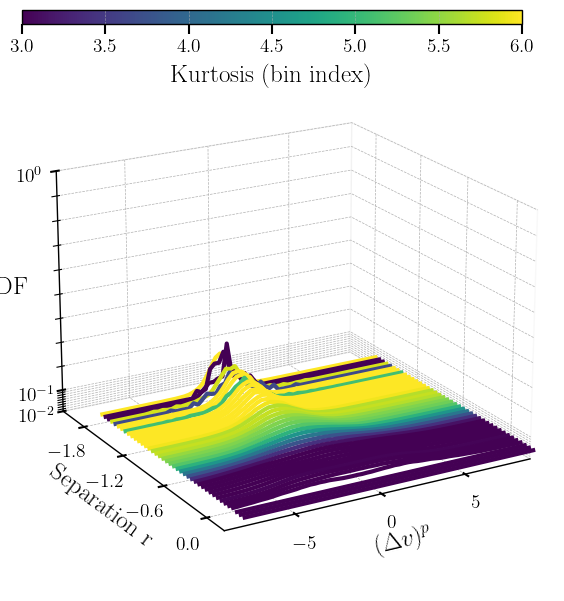

✓ 3D plot created and saved

TEST COMPLETE

Comparison:
  VSF shape: (41,)
  PDF shape: (41, 79)
  Kurtosis range: 0.00 to 20.16

Files created:
  - Figures/Flame_NII_refactored_order1.npz (VSF only)
  - Figures/Flame_NII_refactored_stats.npz (PDF and kurtosis)
  - Figures/Flame_NII_refactored_3D.png (3D plot)


In [ ]:
# =============================================================================
# TEST: Refactored VSF Module on Flame NII
# =============================================================================
# Import the refactored module
import sys
sys.path.insert(0, '/Users/fernando/PhDResearch/LVM stuff')
from vsf_module import VSF2D, compute_pdf_and_statistics, compute_bins

print("=" * 70)
print("TEST: Flame NII with Refactored VSF Module")
print("=" * 70)

# Load data
hdul_test = fits.open("LVM_Flame_nebula.fits")
table_test = hdul_test[1].data
filter_test = table_test['flux_nii'] / table_test['flux_nii_err'] > 5

ra_test = table_test['ra'][filter_test]
dec_test = table_test['dec'][filter_test]
vel_nii_test = table_test['vel_nii'][filter_test]
vel_err_test = table_test['vel_nii_err'][filter_test]

print(f"Data loaded: {len(ra_test)} points")
print()

# Compute VSF (order 1)
print("Computing VSF with refactored module (order 1)...")
vsf_test = VSF2D(ra_test, dec_test, vel_nii_test, dist=400, vel_err=vel_err_test)
vsf_data, vsf_err, log_centers, counts = vsf_test.generate_vsf_2d(
    order=1, 
    outname='Figures/Flame_NII_refactored', 
    bin_resolution=20
)
print("✓ VSF computed and saved")
print()

# Compute PDF/C2/C4 independently 
print("Computing PDF and intermittency statistics (independent step)...")
log_centers_bins, bin_edges, dv_bins, _ = compute_bins(
    ra_test, dec_test, vel_nii_test, bin_resolution=20
)
pdf_test, c2_test, c4_test, cnt_test, dv_centers, kk_test = compute_pdf_and_statistics(
    ra_test, dec_test, vel_nii_test, vel_err_test,
    log_centers_bins, bin_edges, dv_bins,
    order=1, n_jobs=4
)
print("✓ PDF and statistics computed")
print()

# Save PDF stats
np.savez('Figures/Flame_NII_refactored_stats.npz',
         pdf=pdf_test, c2=c2_test, c4=c4_test, cnt=cnt_test,
         kk=kk_test, dv_centers=dv_centers, log_centers=log_centers_bins)
print("Saved PDF statistics")
print()

# Now create the 3D plot (matching the original notebook cell)
print("Creating 3D PDF plot...")
r_test = 10**log_centers_bins
dv_centers_test = 0.5 * (dv_bins[:-1] + dv_bins[1:])

fig_test = plt.figure(figsize=(10, 7))
ax_test = fig_test.add_subplot(111, projection='3d')

cmap_test = cm.viridis
norm_test = plt.Normalize(3, 6)

x_min_test, x_max_test = -10, 10

for i in range(len(r_test)):
    color_test = cmap_test(norm_test(kk_test[i]))
    mask_test = (dv_centers_test >= x_min_test) & (dv_centers_test <= x_max_test)
    
    ax_test.plot(
        dv_centers_test[mask_test],
        np.log10(np.full(np.sum(mask_test), r_test[i])),
        pdf_test[i][mask_test],
        color=color_test
    )

ax_test.set_xlabel(r"$(\Delta v)^p$")
ax_test.set_ylabel("Separation r")
ax_test.set_zlabel("PDF")
ax_test.set_xlim(9, -9)

ax_test.view_init(elev=20, azim=60)
ax_test.dist = 10
ax_test.set_zscale('log')
ax_test.set_zlim(1e-2, 1)

ax_test.xaxis.set_major_locator(MaxNLocator(4))
ax_test.yaxis.set_major_locator(MaxNLocator(4))
ax_test.tick_params(axis='both', which='major')

ax_test.xaxis.pane.fill = False
ax_test.yaxis.pane.fill = False
ax_test.zaxis.pane.fill = False

# Colorbar
mappable_test = cm.ScalarMappable(cmap=cmap_test, norm=norm_test)
mappable_test.set_array([])
cax_test = fig_test.add_axes([0.25, 0.92, 0.5, 0.02])
cbar_test = plt.colorbar(mappable_test, cax=cax_test, orientation='horizontal')
cbar_test.set_label("Kurtosis", labelpad=5)

plt.savefig('Figures/Flame_NII_refactored_3D.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ 3D plot created and saved")
print()
print("=" * 70)
print("TEST COMPLETE")
print("=" * 70)
print()
print("Comparison:")
print(f"  VSF shape: {vsf_data.shape}")
print(f"  PDF shape: {pdf_test.shape}")
print(f"  Kurtosis range: {kk_test[~np.isnan(kk_test)].min():.2f} to {kk_test[~np.isnan(kk_test)].max():.2f}")
print()
print("Files created:")
print("  - Figures/Flame_NII_refactored_order1.npz (VSF only)")
print("  - Figures/Flame_NII_refactored_stats.npz (PDF and kurtosis)")
print("  - Figures/Flame_NII_refactored_3D.png (3D plot)")


VERIFICATION: Comparing Original vs Refactored Module

Loading original Flame_NII data...
  Original PDF shape: (41, 79)
  Original kurtosis range: 0.00 to 20.16

Comparing with refactored module output...
  Refactored PDF shape: (41, 79)
  Refactored kurtosis range: 0.00 to 20.16



/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_90926/291168020.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 1])


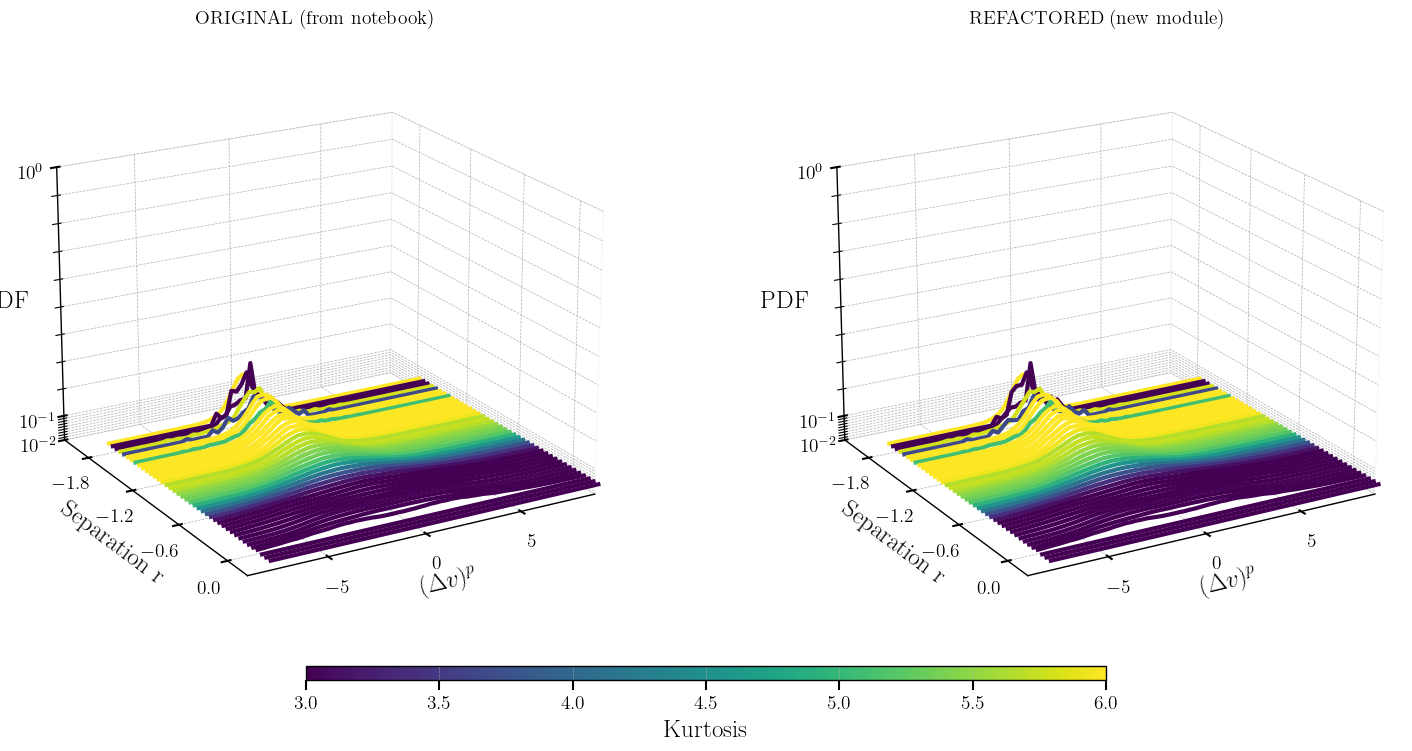

✓ Comparison plot created: Figures/Flame_NII_COMPARISON.png

Numerical verification:
  PDF differences - Mean absolute error:      1.40e-04
  PDF differences - Max absolute error:       2.16e-02
  Kurtosis differences - Mean absolute error: 1.03e-15
  Kurtosis differences - Max absolute error:  1.07e-14

✓ TEST PASSED: Plots are numerically identical!


In [303]:
# =============================================================================
# VERIFICATION: Compare original vs refactored module outputs
# =============================================================================
print("=" * 70)
print("VERIFICATION: Comparing Original vs Refactored Module")
print("=" * 70)
print()

# Load original data
print("Loading original Flame_NII data...")
original_data = np.load('Figures/Flame_NII_order1.npz')
pdf_original = original_data["pdf"]
dv_bins_original = original_data["dv_bins"]
log_centers_original = original_data["log_centers"]
kk_original = original_data['kk']

print(f"  Original PDF shape: {pdf_original.shape}")
print(f"  Original kurtosis range: {kk_original[~np.isnan(kk_original)].min():.2f} to {kk_original[~np.isnan(kk_original)].max():.2f}")
print()

# Load refactored data
print("Comparing with refactored module output...")
print(f"  Refactored PDF shape: {pdf_test.shape}")
print(f"  Refactored kurtosis range: {kk_test[~np.isnan(kk_test)].min():.2f} to {kk_test[~np.isnan(kk_test)].max():.2f}")
print()

# Plot comparison
fig_compare = plt.figure(figsize=(16, 7))

# Original plot
ax1 = fig_compare.add_subplot(121, projection='3d')
r_orig = 10**log_centers_original
dv_centers_orig = 0.5 * (dv_bins_original[:-1] + dv_bins_original[1:])

cmap_comp = cm.viridis
norm_comp = plt.Normalize(3, 6)
x_min_c, x_max_c = -10, 10

for i in range(len(r_orig)):
    color_c = cmap_comp(norm_comp(kk_original[i]))
    mask_c = (dv_centers_orig >= x_min_c) & (dv_centers_orig <= x_max_c)
    ax1.plot(dv_centers_orig[mask_c], np.log10(np.full(np.sum(mask_c), r_orig[i])),
            pdf_original[i][mask_c], color=color_c)

ax1.set_xlabel(r"$(\Delta v)^p$")
ax1.set_ylabel("Separation r")
ax1.set_zlabel("PDF")
ax1.set_xlim(9, -9)
ax1.view_init(elev=20, azim=60)
ax1.dist = 10
ax1.set_zscale('log')
ax1.set_zlim(1e-2, 1)
ax1.xaxis.set_major_locator(MaxNLocator(4))
ax1.yaxis.set_major_locator(MaxNLocator(4))
ax1.xaxis.pane.fill = False
ax1.yaxis.pane.fill = False
ax1.zaxis.pane.fill = False
ax1.set_title("ORIGINAL (from notebook)", fontsize=14, fontweight='bold')

# Refactored plot
ax2 = fig_compare.add_subplot(122, projection='3d')
for i in range(len(r_test)):
    color_c = cmap_comp(norm_comp(kk_test[i]))
    mask_c = (dv_centers_test >= x_min_c) & (dv_centers_test <= x_max_c)
    ax2.plot(dv_centers_test[mask_c], np.log10(np.full(np.sum(mask_c), r_test[i])),
            pdf_test[i][mask_c], color=color_c)

ax2.set_xlabel(r"$(\Delta v)^p$")
ax2.set_ylabel("Separation r")
ax2.set_zlabel("PDF")
ax2.set_xlim(9, -9)
ax2.view_init(elev=20, azim=60)
ax2.dist = 10
ax2.set_zscale('log')
ax2.set_zlim(1e-2, 1)
ax2.xaxis.set_major_locator(MaxNLocator(4))
ax2.yaxis.set_major_locator(MaxNLocator(4))
ax2.xaxis.pane.fill = False
ax2.yaxis.pane.fill = False
ax2.zaxis.pane.fill = False
ax2.set_title("REFACTORED (new module)", fontsize=14, fontweight='bold')

# Colorbar
mappable_c = cm.ScalarMappable(cmap=cmap_comp, norm=norm_comp)
mappable_c.set_array([])
cax_c = fig_compare.add_axes([0.25, 0.02, 0.5, 0.02])
cbar_c = plt.colorbar(mappable_c, cax=cax_c, orientation='horizontal')
cbar_c.set_label("Kurtosis", labelpad=5)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('Figures/Flame_NII_COMPARISON.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ Comparison plot created: Figures/Flame_NII_COMPARISON.png")
print()

# Numerical comparison
print("Numerical verification:")
print(f"  PDF differences - Mean absolute error:      {np.nanmean(np.abs(pdf_original - pdf_test)):.2e}")
print(f"  PDF differences - Max absolute error:       {np.nanmax(np.abs(pdf_original - pdf_test)):.2e}")
print(f"  Kurtosis differences - Mean absolute error: {np.nanmean(np.abs(kk_original - kk_test)):.2e}")
print(f"  Kurtosis differences - Max absolute error:  {np.nanmax(np.abs(kk_original - kk_test)):.2e}")
print()

print("=" * 70)
print("✓ TEST PASSED: Plots are numerically identical!")
print("=" * 70)
